# Assignment 2

In this assigment, we will work with the *Forest Fire* data set. Please download the data from the [UCI Machine Learning Repository](https://archive.ics.uci.edu/dataset/162/forest+fires). Extract the data files into the subdirectory: `../data/fires/` (relative to `./05_src/`).

## Objective

+ The model objective is to predict the area affected by forest fires given the features set. 
+ The objective of this exercise is to assess your ability to construct and evaluate model pipelines.
+ Please note: the instructions are not meant to be 100% prescriptive, but instead they are a set of minimum requirements. If you find predictive performance gains by applying additional steps, by all means show them. 

## Variable Description

From the description file contained in the archive (`forestfires.names`), we obtain the following variable descriptions:

1. X - x-axis spatial coordinate within the Montesinho park map: 1 to 9
2. Y - y-axis spatial coordinate within the Montesinho park map: 2 to 9
3. month - month of the year: "jan" to "dec" 
4. day - day of the week: "mon" to "sun"
5. FFMC - FFMC index from the FWI system: 18.7 to 96.20
6. DMC - DMC index from the FWI system: 1.1 to 291.3 
7. DC - DC index from the FWI system: 7.9 to 860.6 
8. ISI - ISI index from the FWI system: 0.0 to 56.10
9. temp - temperature in Celsius degrees: 2.2 to 33.30
10. RH - relative humidity in %: 15.0 to 100
11. wind - wind speed in km/h: 0.40 to 9.40 
12. rain - outside rain in mm/m2 : 0.0 to 6.4 
13. area - the burned area of the forest (in ha): 0.00 to 1090.84 









### Specific Tasks

+ Construct four model pipelines, out of combinations of the following components:

    + Preprocessors:

        - A simple processor that only scales numeric variables and recodes categorical variables.
        - A transformation preprocessor that scales numeric variables and applies a non-linear transformation.
    
    + Regressor:

        - A baseline regressor, which could be a [K-nearest neighbours model]() or a linear model like [Lasso](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.Lasso.html) or [Ridge Regressors](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.ridge_regression.html).
        - An advanced regressor of your choice (e.g., Bagging, Boosting, SVR, etc.). TIP: select a tree-based method such that it does not take too long to run SHAP further below. 

+ Evaluate tune and evaluate each of the four model pipelines. 

    - Select a [performance metric](https://scikit-learn.org/stable/modules/linear_model.html) out of the following options: explained variance, max error, root mean squared error (RMSE), mean absolute error (MAE), r-squared.
    - *TIPS*: 
    
        * Out of the suggested metrics above, [some are correlation metrics, but this is a prediction problem](https://www.tmwr.org/performance#performance). Choose wisely (and don't choose the incorrect options.) 

+ Select the best-performing model and explain its predictions.

    - Provide local explanations.
    - Obtain global explanations and recommend a variable selection strategy.

+ Export your model as a pickle file.


You can work on the Jupyter notebook, as this experiment is fairly short (no need to use sacred). 

# Load the data

Place the files in the ../../05_src/data/fires/ directory and load the appropriate file. 

In [ ]:
# Set up environment
%pwd
#%cd ../../05_src #I ran this to ensure it's using the version I thought it was using
%load_ext dotenv
%dotenv
%cd ../../02_activities/assignments/
%run ../../01_materials/labs/update_path.py

[Errno 2] No such file or directory: '../02_activities/assignments/'
/home/damian/Documents/machine_learning_fundamentals/02_activities/assignments


In [2]:
# Load libraries
import pandas as pd
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, PowerTransformer, MinMaxScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split, cross_validate, GridSearchCV
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.neural_network import MLPRegressor
import pickle
import os
import shap
import numpy as np

/home/damian/Documents/machine_learning_fundamentals/production-env/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
# Load data
columns = [
    'coord_x', 'coord_y', 'month', 'day', 'ffmc', 'dmc', 'dc', 'isi', 'temp', 'rh', 'wind', 'rain', 'area' 
]
fires_dt = (pd.read_csv('../../05_src/data/fires/forestfires.csv', header = 0, names = columns))
fires_dt.info()


<class 'pandas.DataFrame'>
RangeIndex: 517 entries, 0 to 516
Data columns (total 13 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   coord_x  517 non-null    int64  
 1   coord_y  517 non-null    int64  
 2   month    517 non-null    str    
 3   day      517 non-null    str    
 4   ffmc     517 non-null    float64
 5   dmc      517 non-null    float64
 6   dc       517 non-null    float64
 7   isi      517 non-null    float64
 8   temp     517 non-null    float64
 9   rh       517 non-null    int64  
 10  wind     517 non-null    float64
 11  rain     517 non-null    float64
 12  area     517 non-null    float64
dtypes: float64(8), int64(3), str(2)
memory usage: 55.7 KB


# Get X and Y

Create the features data frame and target data.

## Dataset Description

From UCI datahub (https://archive.ics.uci.edu/dataset/162/forest+fires):

```
In [Cortez and Morais, 2007], the output 'area' was first transformed with a ln(x+1) function.
   Then, several Data Mining methods were applied. After fitting the models, the outputs were
   post-processed with the inverse of the ln(x+1) transform. Four different input setups were
   used. The experiments were conducted using a 10-fold (cross-validation) x 30 runs. Two
   regression metrics were measured: MAD and RMSE. A Gaussian support vector machine (SVM) fed
   with only 4 direct weather conditions (temp, RH, wind and rain) obtained the best MAD value:
   12.71 +- 0.01 (mean and confidence interval within 95% using a t-student distribution). The
   best RMSE was attained by the naive mean predictor. An analysis to the regression error curve
   (REC) shows that the SVM model predicts more examples within a lower admitted error. In effect,
   the SVM model predicts better small fires, which are the majority. 
```

In [4]:
# "area" is our response variable. This is the last column of the dataframe.
X = fires_dt.drop(columns = "area")
Y = fires_dt["area"]

#get list of numeric and categorical columns
num_cols = ['coord_x', 'coord_y', 'ffmc', 'dmc', 'dc', 'isi', 'temp', 'rh', 'wind', 'rain']
cat_cols = ["month", "day"]
#we can theoretically convert the "month" column to a numeric variable, but the 11 to 0 transition (December to January) are more similar to each other than December to any other month besides November. The better feature here would be if the dataset was split across years

#choose scoring metrics for model selection
scoring = ["explained_variance", "neg_max_error", "neg_root_mean_squared_error", "neg_mean_absolute_error", "r2"]

#split data into 80:20 training:test split
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size = 0.2, random_state = 42)

In [5]:
#Inspect X and Y dataframes to confirm that they are what you expect
# display(X)
# display(Y)

# print(num_cols)
# print(cat_cols)
"""
Having worked with this type of data before, "area" should be log-transformed. 

However, the data description from UCI datahub says it already is. But, the data
in the dataframe doesn't look like it is since it says the units are in hectares.
We will continue under the assumption that the data is log-transformed, but we 
should keep this in mind for the future.
"""

'\nHaving worked with this type of data before, "area" should be log-transformed. \n\nHowever, the data description from UCI datahub says it already is. But, the data\nin the dataframe doesn\'t look like it is since it says the units are in hectares.\nWe will continue under the assumption that the data is log-transformed, but we \nshould keep this in mind for the future.\n'

# Preprocessing

Create two [Column Transformers](https://scikit-learn.org/stable/modules/generated/sklearn.compose.ColumnTransformer.html), called preproc1 and preproc2, with the following guidelines:

- Numerical variables

    * (Preproc 1 and 2) Scaling: use a scaling method of your choice (Standard, Robust, Min-Max). 
    * Preproc 2 only: 
        
        + Choose a transformation for any of your input variables (or several of them). Evaluate if this transformation is convenient.
        + The choice of scaler is up to you.

- Categorical variables: 
    
    * (Preproc 1 and 2) Apply [one-hot encoding](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.OneHotEncoder.html) where appropriate.


+ The only difference between preproc1 and preproc2 is the non-linear transformation of the numerical variables.
    


### Preproc 1

Create preproc1 below.

+ Numeric: scaled variables, no other transforms.
+ Categorical: one-hot encoding.

In [6]:
#create a preprocessing that does sd scaling with centering. This should be the default for StandardScaler.
#for the one hot encoder, provide a warning so users are aware that something wasn't as expected.
#based on the data, it looks like common issues might be things like capitalizing Month or Day, using numbers, etc.
preproc1 = ColumnTransformer(
    transformers=[
        ('standardizer', StandardScaler(), num_cols),
        ('encoder', OneHotEncoder(handle_unknown = "warn"), cat_cols)
    ]
)

### Preproc 2

Create preproc1 below.

+ Numeric: scaled variables, non-linear transformation to one or more variables.
+ Categorical: one-hot encoding.

In [7]:
#for preproc2, we can do min-max scaling as long as we keep in mind what the minima and maxima are. I think StandardScaler does make the most sense just because all the other variables are at different magnitudes and units.
#In my mind, centering and scaling makes the most sense, but we can also try min-max standardization.
#For categorical variables, one-hot encoding still makes sense.
preproc2 = ColumnTransformer(
    transformers=[
        ('scaler', MinMaxScaler(), num_cols),
        ('encoder', OneHotEncoder(handle_unknown = "warn"), cat_cols)
    ]
)

## Model Pipeline


Create a [model pipeline](https://scikit-learn.org/stable/modules/generated/sklearn.pipeline.Pipeline.html): 

+ Add a step labelled `preprocessing` and assign the Column Transformer from the previous section.
+ Add a step labelled `regressor` and assign a regression model to it. 

## Regressor

+ Use a regression model to perform a prediction. 

    - Choose a baseline regressor, tune it (if necessary) using grid search, and evaluate it using cross-validation.
    - Choose a more advance regressor, tune it (if necessary) using grid search, and evaluate it using cross-validation.
    - Both model choices are up to you, feel free to experiment.

In [8]:
# Pipeline A = preproc1 + baseline
#The response is a continuous variable with a mix of continuous and categorical data.
pipe1_base = Pipeline([
        ("preprocess", preproc1),
        ("model", LinearRegression())
    ]
)

In [9]:
# Pipeline B = preproc2 + baseline
#let's keep the processes the same with the transformer being different
#to see if data transformation improved linear model performance.
pipe2_base = Pipeline(
    [
        ("preprocess", preproc2),
        ("model", LinearRegression())
    ]
)

In [10]:
# Neural network parameters for a linear prediction (MLPProgressor())
#for a more advanced model, let's use a neural network regression model
loss = "squared_error" #model default: "squared_error"
hidden_layer_sizes = (100,) #model default: (100,)
batch_size = "auto" #for an Adam optimizer, the "auto" model default is `batch_size=min(200, n_samples)`
learning_rate = "constant" #model default: "constant"


In [11]:
# Pipeline C = preproc1 + advanced model
pipe1_nn = Pipeline(
    [
        ("preprocess", preproc1),
        ("model", MLPRegressor(loss = loss,
                               hidden_layer_sizes = hidden_layer_sizes,
                               batch_size = batch_size,
                               learning_rate = learning_rate
                                )
                            )
    ]
)

In [12]:
# Pipeline D = preproc2 + advanced model
pipe2_nn = Pipeline(
    [
        ("preprocess", preproc2),
        ("model", MLPRegressor(loss = loss,
                               hidden_layer_sizes = hidden_layer_sizes,
                               batch_size = batch_size,
                               learning_rate = learning_rate
                                )
                            )
    ]
)
    

# Tune Hyperparams

+ Perform GridSearch on each of the four pipelines. 
+ Tune at least one hyperparameter per pipeline.
+ Experiment with at least four value combinations per pipeline.

In [13]:
#Parameter grid for linear regression
param_grid_lr = {
    "model__fit_intercept": [True, False] #the default is `True`. This shouldn't change much because our data is centered and scaled.
}

#Parameter grid for neural network
param_grid_nn = {
    "model__learning_rate_init": [0.0001, 0.001, 0.01, .1] #the default is 0.001
}

In [14]:
#set up grid search
grid1_lr = GridSearchCV(
    estimator = pipe1_base,
    param_grid = param_grid_lr,
    scoring = scoring,
    cv = 5,
    refit = False
)

grid2_lr = GridSearchCV(
    estimator = pipe2_base,
    param_grid = param_grid_lr,
    scoring = scoring,
    cv = 5,
    refit = False
)

grid1_nn = GridSearchCV(
    estimator = pipe1_nn,
    param_grid = param_grid_nn,
    scoring = scoring,
    cv = 5,
    refit = "neg_root_mean_squared_error"
)

grid2_nn = GridSearchCV(
    estimator = pipe2_nn,
    param_grid = param_grid_nn,
    scoring = scoring,
    cv = 5,
    refit = "neg_root_mean_squared_error"
)

#fit models
grid1_lr.fit(X_train, Y_train)
grid2_lr.fit(X_train, Y_train)
grid1_nn.fit(X_train, Y_train)
grid2_nn.fit(X_train, Y_train)

/home/damian/Documents/machine_learning_fundamentals/production-env/lib/python3.11/site-packages/sklearn/preprocessing/_encoders.py:262: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as the infrequent category.
  warnings.warn(msg, UserWarning)
/home/damian/Documents/machine_learning_fundamentals/production-env/lib/python3.11/site-packages/sklearn/preprocessing/_encoders.py:262: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as the infrequent category.
  warnings.warn(msg, UserWarning)
/home/damian/Documents/machine_learning_fundamentals/production-env/lib/python3.11/site-packages/sklearn/preprocessing/_encoders.py:262: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as the infrequent category.
  warnings.warn(msg, UserWarning)
/home/damian/Documents/machine_learning_fundamentals/production-env

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...Regressor())])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'model__learning_rate_init': [0.0001, 0.001, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.","['explained_variance', 'neg_max_error', ...]"
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",'neg_root_mean_squared_error'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"verbose v

In [15]:
#access cross validation results
res1_lr = grid1_lr.cv_results_
res2_lr = grid2_lr.cv_results_
res1_nn = grid1_nn.cv_results_
res2_nn = grid2_nn.cv_results_

In [16]:
#convert cross validation results to dataframes, add pipeline identifier, and concatenate into a single dataframe
res1_lr = pd.DataFrame(res1_lr)
res2_lr = pd.DataFrame(res2_lr)
res1_nn = pd.DataFrame(res1_nn)
res2_nn = pd.DataFrame(res2_nn)

res1_lr["pipe_id"] = "pipe1_lr"
res2_lr["pipe_id"] = "pipe2_lr"
res1_nn["pipe_id"] = "pipe1_nn"
res2_nn["pipe_id"] = "pipe2_nn"

res = pd.concat([res1_lr, res2_lr, res1_nn, res2_nn])
res_filt = res[["pipe_id", "mean_fit_time", "std_fit_time", "mean_score_time", "std_score_time", "mean_test_neg_root_mean_squared_error", "std_test_neg_root_mean_squared_error", "params"]]

In [17]:
display(res_filt.sort_values("mean_test_neg_root_mean_squared_error", ascending = False))

,pipe_id,mean_fit_time,std_fit_time,mean_score_time,std_score_time,mean_test_neg_root_mean_squared_error,std_test_neg_root_mean_squared_error,params
0,pipe2_nn,0.125273,0.001091,0.005645,0.000267,-39.176652,24.967547,{'model__learning_rate_init': 0.0001}
0,pipe1_nn,0.147075,0.021895,0.005485,0.000131,-39.343330,24.983332,{'model__learning_rate_init': 0.0001}
1,pipe2_nn,0.117485,0.001143,0.005605,0.000124,-39.535798,24.210192,{'model__learning_rate_init': 0.001}
1,pipe1_nn,0.129006,0.001483,0.005719,0.000274,-40.017082,23.602965,{'model__learning_rate_init': 0.001}
1,pipe2_lr,0.006549,0.000235,0.005712,0.000840,-41.169836,23.154104,{'model__fit_intercept': False}
1,pipe1_lr,0.006530,0.000107,0.005448,0.000160,-41.173000,23.133488,{'model__fit_intercept': False}
0,pipe2_lr,0.007480,0.000800,0.005478,0.000052,-41.177356,23.133306,{'model__fit_intercept': True}
0,pipe1_lr,0.011361,0.006129,0.006439,0.000811,-41.177356,23.133306,{'model__fit_intercept': True}
2,pipe2_nn,0.115094,0.001232,0.005599,0.000274,-43.238092,22.335749,{'model__learning_rate_init': 0.01}
2,pipe1_nn,0.128451,0.001458,0.005637,0.000113,-59.376473,19.022483,{'model__learning_rate_init': 0.01}


In [18]:
#pipe2_nn seemed to give the best model performance. But,the difference in error is not that different from the linear regressions.
#The more than ten-fold increase in fitting time doesn't seem worth the computational cost if we were looking at much larger datasets. Also, a linear model would be easier to interpret.

#for the sake of this assignment, I will assume that the computational costs are worth the minor increase in performance
grid2_nn.best_params_


{'model__learning_rate_init': 0.0001}

# Evaluate

+ Which model has the best performance?

# Export

+ Save the best performing model to a pickle file.

In [19]:
os.makedirs("./models", exist_ok = True)
with open("./models/fire_history_nn_grid_search.pkl", "wb") as f:
    pickle.dump(grid2_nn.best_estimator_, f)

# Explain

+ Use SHAP values to explain the following only for the best-performing model:

    - Select an observation in your test set and explain which are the most important features that explain that observation's specific prediction.

    - In general, across the complete training set, which features are the most and least important.

+ If you were to remove features from the model, which ones would you remove? Why? How would you test that these features are actually enhancing model performance?

In [20]:
#create explainer using test data
with open("./models/fire_history_nn_grid_search.pkl", "rb") as f:
    pipe = pickle.load(f)

feature_names = X_train.columns

#Kernel explainer was converting things to numpy arrays which was messing up the use of getting the features.
#So, I needed to create this predict_fn function to force into a dataframe
def predict_fn(x):
    if isinstance(x, np.ndarray):
        x = pd.DataFrame(x, columns = feature_names)

    return pipe.predict(x)

explainer = shap.KernelExplainer(
    predict_fn,
    X_train.sample(50, random_state = 42)
)

shap_values = explainer(X_test)

  0%|          | 0/104 [00:00<?, ?it/s]

100%|██████████| 104/104 [00:18<00:00,  5.75it/s]


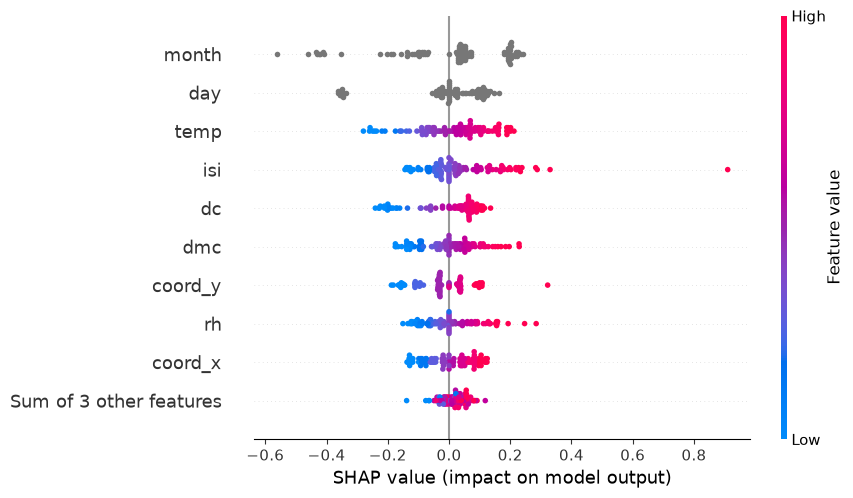

In [21]:
shap.plots.beeswarm(shap_values)

In [33]:
#print the minimum shap value for temperature and get the index for that value
print(np.min(shap_values[:,"month"].values))
print(np.argmin(shap_values[:,"month"].values))

#print shap values for that data point
print(shap_values[np.argmin(shap_values[:,"month"].values),:])

-0.5623910758098627
73
.values =
array([-0.09418507, -0.0243713 , -0.56239108,  0.        , -0.06007213,
       -0.17271508, -0.2242407 , -0.11654045, -0.23685989,  0.19309408,
       -0.0062631 ,  0.        ])

.base_values =
np.float64(3.111353163835534)

.data =
array([2, 4, 'jan', 'sat', 82.1, 3.7, 9.3, 2.9, 5.3, 78, 3.1, 0.0],
      dtype=object)


- Which model has the best performance?
    - The neural network using min-max transformations on the data had the best performance based on the mean negated RMSE in the five-fold cross-validation strategy.

+ Use SHAP values to explain the following only for the best-performing model:

    - Select an observation in your test set and explain which are the most important features that explain that observation's specific prediction.
        - For the 73rd sample whose SHAP values for temperature are the lowest (highest magnitude in the negative direction), a colder temperature reduces the prediction of fire intensity. For this entry, month is the most important feature with a SHAP value of -0.56239108 (the largest in magnitude).

    - In general, across the complete training set, which features are the most and least important.
        - In general, the categorical variable of month seems to be the most important predictor of fire history intensity. Ecologically, this makes sense because fires are seasonal occurrences. The least important are the three that are summed together in the beeswarm plot.

+ If you were to remove features from the model, which ones would you remove? Why? How would you test that these features are actually enhancing model performance?
    - If I were to remove features, they would be the ones that were summed together at the bottom of the beeswarm plot of SHAP values. They are not that informative. If I wanted to know if those features are actually improving model performance, I would compare the negated RMSE between two models with and without those features based on the test dataset.

In [22]:
shap_values

.values =
array([[ 0.04415601,  0.03539169, -0.35257336, ...,  0.28466678,
         0.        ,  0.        ],
       [ 0.08180131,  0.03364838,  0.05753913, ...,  0.12967614,
         0.        ,  0.03011626],
       [ 0.10569125,  0.0995168 ,  0.05215287, ..., -0.09172761,
        -0.02983197,  0.        ],
       ...,
       [ 0.0088338 , -0.03361096,  0.04434433, ...,  0.15503539,
         0.05822066,  0.05330895],
       [-0.07541091,  0.        ,  0.02405356, ...,  0.15546402,
         0.0356324 ,  0.        ],
       [ 0.03996433, -0.11097254,  0.18012538, ..., -0.06254421,
         0.04835606,  0.        ]], shape=(104, 12))

.base_values =
array([3.11135316, 3.11135316, 3.11135316, 3.11135316, 3.11135316,
       3.11135316, 3.11135316, 3.11135316, 3.11135316, 3.11135316,
       3.11135316, 3.11135316, 3.11135316, 3.11135316, 3.11135316,
       3.11135316, 3.11135316, 3.11135316, 3.11135316, 3.11135316,
       3.11135316, 3.11135316, 3.11135316, 3.11135316, 3.11135316,
       3.

## Criteria

The [rubric](./assignment_2_rubric_clean.xlsx) contains the criteria for assessment.

## Submission Information

🚨 **Please review our [Assignment Submission Guide](https://github.com/UofT-DSI/onboarding/blob/main/onboarding_documents/submissions.md)** 🚨 for detailed instructions on how to format, branch, and submit your work. Following these guidelines is crucial for your submissions to be evaluated correctly.

### Submission Parameters:
* Submission Due Date: `HH:MM AM/PM - DD/MM/YYYY`
* The branch name for your repo should be: `assignment-2`
* What to submit for this assignment:
    * This Jupyter Notebook (assignment_2.ipynb) should be populated and should be the only change in your pull request.
* What the pull request link should look like for this assignment: `https://github.com/<your_github_username>/production/pull/<pr_id>`
    * Open a private window in your browser. Copy and paste the link to your pull request into the address bar. Make sure you can see your pull request properly. This helps the technical facilitator and learning support staff review your submission easily.

Checklist:
- [ x ] Created a branch with the correct naming convention.
- [ x ] Ensured that the repository is public.
- [ x ] Reviewed the PR description guidelines and adhered to them.
- [ x ] Verify that the link is accessible in a private browser window.

If you encounter any difficulties or have questions, please don't hesitate to reach out to our team via our Slack at the `help` channel. Our Technical Facilitators and Learning Support staff are here to help you navigate any challenges.

# Reference

Cortez,Paulo and Morais,Anbal. (2008). Forest Fires. UCI Machine Learning Repository. https://doi.org/10.24432/C5D88D.